# 📊 Análisis Exploratorio de Datos (EDA) - Impacto Sanitario COVID-19 en EE.UU.
---

## 1. Configuración del Entorno y Carga de Datos
> **Objetivo:** Definir la infraestructura de trabajo, importar bibliotecas esenciales (Pandas, NumPy, Matplotlib, Seaborn) y cargar el dataset reducido con las 10 variables clave seleccionadas para el estudio sanitario.

In [ ]:
# Carga de paquetes y dataframe
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

import sys
print(sys.executable)

# Configuración visual para los gráficos
#sns.set_style("whitegrid")
#plt.rcParams['figure.figsize'] = (10, 6)
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

In [ ]:
# Usamos el dataset histórico consolidado (enfocado en EE.UU.)
# URL del archivo original 'all-states-history.csv' en un repositorio espejo público de GitHub
url = 'https://raw.githubusercontent.com/DataByteSun/CSV-Data-Agent-with-DeepSeek-R1/main/all-states-history.csv'


# Cargar directamente el DataFrame en Pandas
df = pd.read_csv(url)

print("¡Datos cargados con éxito!")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")

# Resetear el índice
#df_us = df_us.reset_index(drop=True)

Eliminar columnas irrelevantes

In [ ]:
print(f'Columnas antes: {df.shape[1]}')  # Debe mostrar 41

# Lista corregida
columnas_a_descartar = [
    'positiveScore',
    'recovered',
    'deathConfirmed',
    'deathProbable',
    'negativeTestsAntibody',
    'negativeTestsPeopleAntibody',
    'positiveTestsAntibody',
    'positiveTestsPeopleAntibody',
    'positiveTestsAntigen',
    'totalTestsAntibody',
    'totalTestsPeopleAntibody',
]

# Aplicar el drop
df_reducido = df.drop(columns=columnas_a_descartar)

print(f'Columnas después: {df_reducido.shape[1]}')
print(f"Filas: {df_reducido.shape[0]}, Columnas: {df_reducido.shape[1]}")

print(df_reducido.columns.tolist())

Ver las primeras filas

In [ ]:
df_reducido.head()

Dimensiones del dataset,Información general y tipos de datos

In [ ]:
print(f"Filas: {df_reducido.shape[0]}, Columnas: {df_reducido.shape[1]}")

# Muestra las 30 columnas completas de df_reducido sin cortes
for i, col in enumerate(df_reducido.columns):
    no_nulos = df_reducido[col].notnull().sum()
    tipo = df_reducido[col].dtype
    print(f"[{i:02d}] {col:<35} | Tipo: {tipo} | No nulos: {no_nulos}")

df_reducido.info(verbose=True)

print(df_reducido.columns.tolist())

Estadística Descriptiva

In [ ]:
df_reducido.describe()

Estadística para columnas categóricas

In [ ]:
df_reducido.describe(include='object')

## 2.Diagnóstico de Calidad e Integridad de los Datos, Tratamiento de Valores Nulos
Identificar variable relevantes, valores faltantes (Missing Values), Imputación y ajustes de ceros/ffill

In [ ]:
# Definir las 10 variables clave adaptadas a los nombres reales de tu dataset
columns_to_keep = [
    'date',
    'state',
    'positive',  # Total acumulado de casos positivos
    'positiveIncrease',  # Casos nuevos diarios
    'death',  # Total acumulado de muertes
    'deathIncrease',  # Muertes nuevas diarias
    'hospitalizedCurrently',  # Pacientes hospitalizados actuales
    'inIcuCurrently',  # Pacientes en UCI actuales
    'totalTestResults',  # Total acumulado de resultados de pruebas
    'totalTestResultsIncrease',  # Nuevas pruebas diarias
]

# Crear el nuevo DataFrame limpio e independiente
df_clean = df_reducido[columns_to_keep].copy()

# Verificar las dimensiones del resultado
print(df_clean.shape)
df_clean.head()

In [ ]:
print(df_reducido.isnull().sum())

Visualiza valores faltantes

In [ ]:
# Calcula el porcentaje de nulos, redondea y convierte a DataFrame
missing_percent = (
    df_reducido.isnull().sum() / len(df_reducido)
) * 100
df_missing = (
    missing_percent[missing_percent > 0].round(2).to_frame(name='Porcentaje_Nulos (%)')
)

# Crea una función para aplicar el color rojo si el valor es mayor a 50
def resaltar_nulos_altos(val):
    color = 'red' if val > 50 else 'black'
    peso = 'bold' if val > 50 else 'normal'
    return f'color: {color}; font-weight: {peso};'

# 3. Aplicar el estilo y mostrar la tabla interactiva en Jupyter
df_missing.style.map(resaltar_nulos_altos).format('{:.2f}%')

In [ ]:
# Diagnóstico de Calidad e Integridad de los Datos (sobre el dataset filtrado/reducido)
# Asumiendo que 'df_clean' es tu dataframe con las 10 variables clave seleccionadas:
#revisar alternativa solo con df_clean

missing_data = df_clean.isnull().sum()
missing_percent = (df_clean.isnull().sum() / len(df_clean)) * 100

missing_summary = pd.DataFrame({
    'Valores Faltantes': missing_data,
    'Porcentaje (%)': missing_percent
})
print(missing_summary)

# Cálculo de porcentajes de valores nulos
missing_data = df_clean.isnull().mean() * 100
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

# Visualización de la Calidad de Datos
plt.figure(figsize=(8,4))
missing_data.plot(kind='bar', color='#e74c3c')
plt.title('Porcentaje de Valores Faltantes - Variables Clave (Calidad de Datos)')
plt.ylabel('% Valores Nulos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Guardar figura para el Informe Ejecutivo
plt.savefig('figura_1_nulos.png', dpi=300)
plt.show()

Diagnóstico y Tratamiento de Valores Nulos
> **Descripción:** Una vez detectados los valores faltantes, procedemos a su imputación metodológica.
Tratamiento de valores nulos (Imputación y Ajustes)

In [ ]:
# Verificar ANTES de rellenar que el resultado de nulos sea 0 en las columnas críticas
print(df_clean[['positiveIncrease', 'deathIncrease', 'positive', 'death']].isnull().sum())
# Rellenar ceros en métricas de flujo diario donde el nulo representa ausencia de registro inicial
df_clean['positiveIncrease'] = df_clean['positiveIncrease'].fillna(0)
df_clean['deathIncrease'] = df_clean['deathIncrease'].fillna(0)
df_clean['positive'] = df_clean['positive'].ffill().fillna(0)
df_clean['death'] = df_clean['death'].ffill().fillna(0)

# Verificar que el resultado de nulos sea 0 en las columnas críticas
print(df_clean[['positiveIncrease', 'deathIncrease', 'positive', 'death']].isnull().sum())

## 3. Análisis Univariado: Distribución y Asimetría de Variables Críticas
Examinamos la distribución de los casos nuevos diarios y muertes diarias para entender la asimetría y el comportamiento general de la epidemia en EE.UU.

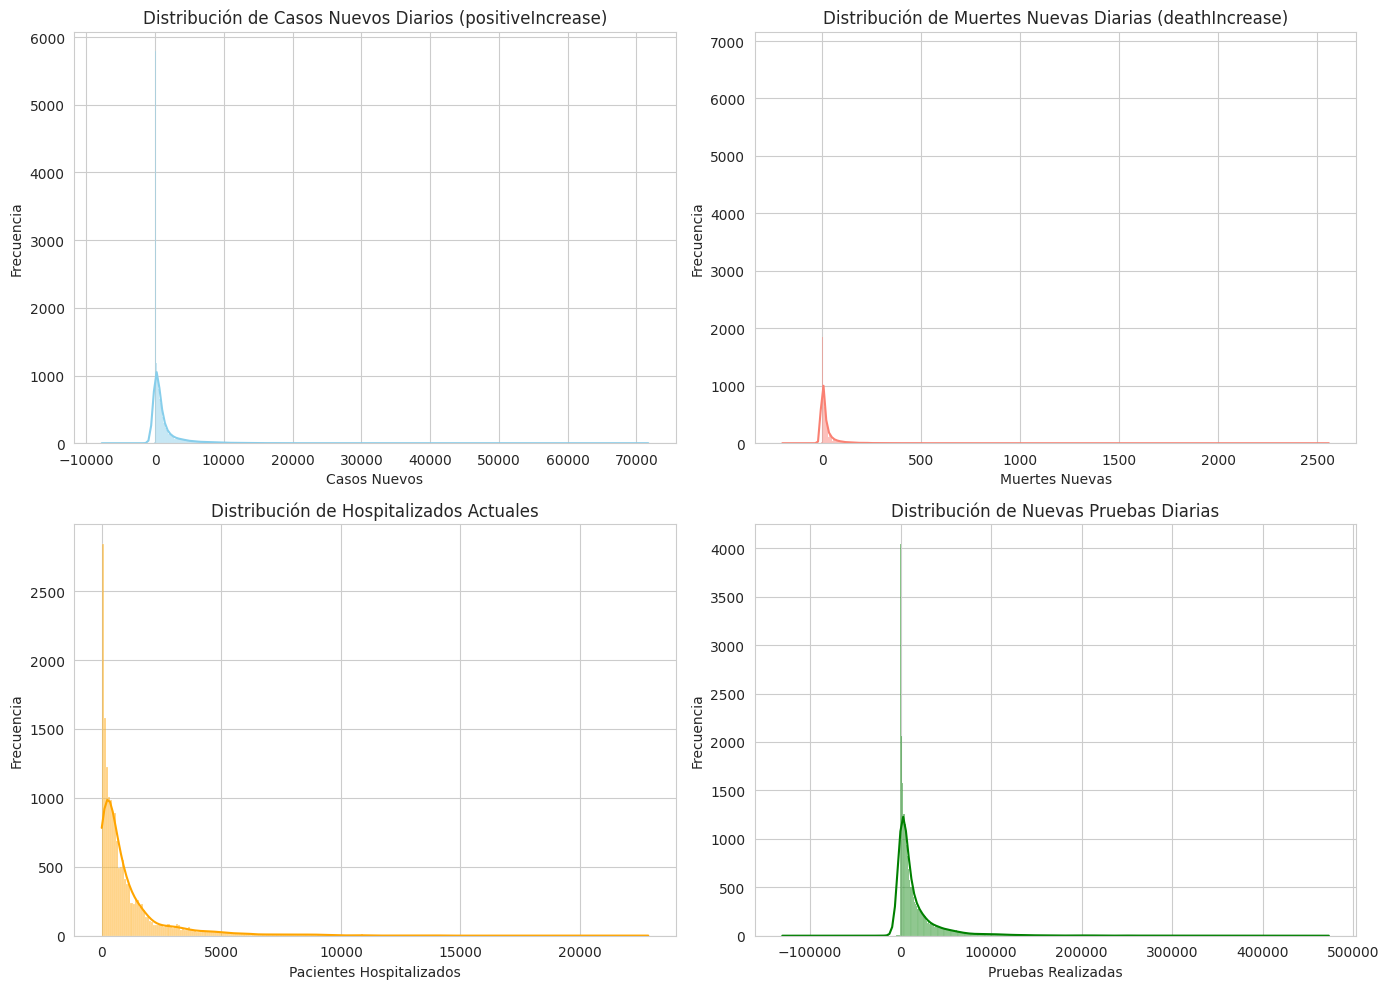

In [26]:
# Configuramos una figura con subplots para ver las distribuciones principales
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Casos nuevos diarios (positiveIncrease)
sns.histplot(df_clean['positiveIncrease'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribución de Casos Nuevos Diarios (positiveIncrease)')
axes[0, 0].set_xlabel('Casos Nuevos')
axes[0, 0].set_ylabel('Frecuencia')

# 2. Muertes nuevas diarias (deathIncrease)
sns.histplot(df_clean['deathIncrease'], kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Distribución de Muertes Nuevas Diarias (deathIncrease)')
axes[0, 1].set_xlabel('Muertes Nuevas')
axes[0, 1].set_ylabel('Frecuencia')

# 3. Hospitalizados actuales (hospitalizedCurrently)
sns.histplot(df_clean['hospitalizedCurrently'].dropna(), kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Distribución de Hospitalizados Actuales')
axes[1, 0].set_xlabel('Pacientes Hospitalizados')
axes[1, 0].set_ylabel('Frecuencia')

# 4. Total de resultados de pruebas diarias (totalTestResultsIncrease)
sns.histplot(df_clean['totalTestResultsIncrease'], kde=True, ax=axes[1, 1], color='green')
axes[1, 1].set_title('Distribución de Nuevas Pruebas Diarias')
axes[1, 1].set_xlabel('Pruebas Realizadas')
axes[1, 1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.savefig('figura_2_distribuciones.png', dpi=300)
plt.show()

## 4. Análisis Temporal y Bivariado: Dinámica de Olas de la Pandemia en EE.UU.
Convertimos la columna de fecha a tipo datetime, ordenamos cronológicamente y agregamos los datos a nivel nacional por día para observar las distintas Olas de contagios y muertes. Evaluación de la evolución cronológica (date_dt) comparando la velocidad de propagación (casos positivos) frente a los indicadores de gravedad (fallecimientos y hospitalizaciones en UCI).

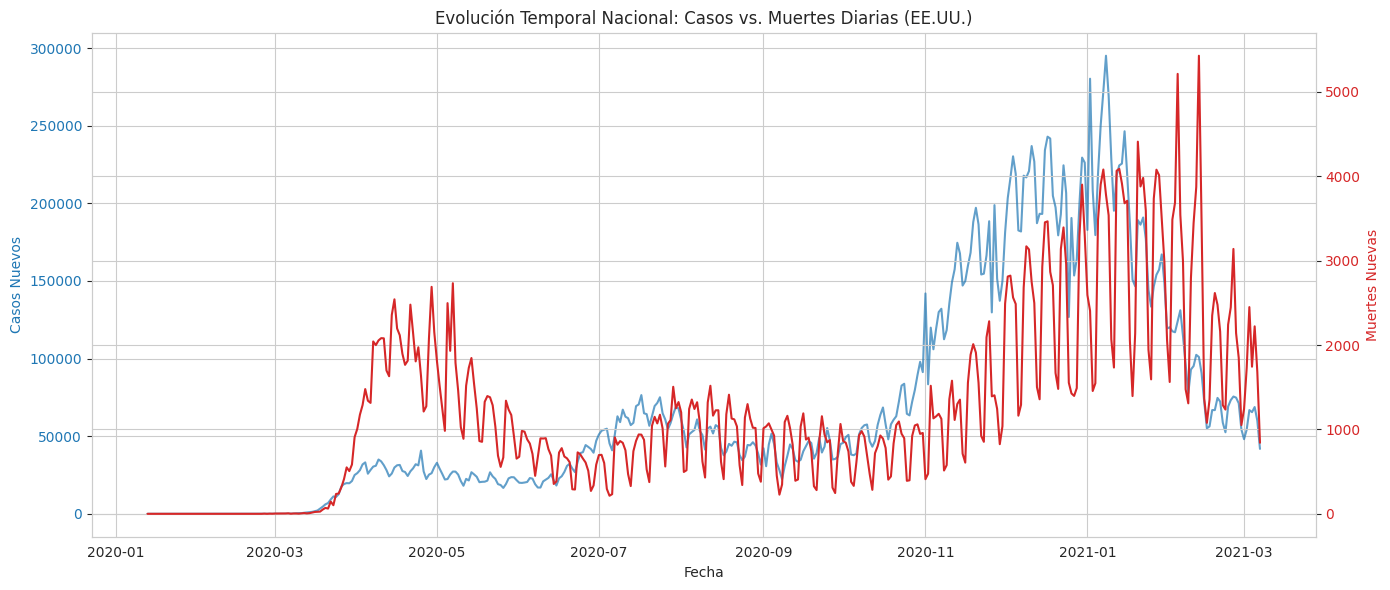

In [34]:
# Convertir la columna date a datetime (el formato original es d-m-Y o similar, revisamos el string: '07-03-2021')
df_clean['date_dt'] = pd.to_datetime(df_clean['date'], format='%d-%m-%Y', errors='coerce')

# Agrupar a nivel nacional (sumando todos los estados por fecha)
df_temporal = df_clean.groupby('date_dt')[['positiveIncrease', 'deathIncrease', 'hospitalizedCurrently']].sum().reset_index()
df_temporal = df_temporal.sort_values('date_dt')

# Gráfico de serie temporal para Casos y Muertes diarias
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(df_temporal['date_dt'], df_temporal['positiveIncrease'], color='tab:blue', label='Casos Nuevos Diarios', alpha=0.7)
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Casos Nuevos', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(df_temporal['date_dt'], df_temporal['deathIncrease'], color='tab:red', label='Muertes Nuevas Diarias', linewidth=1.5)
ax2.set_ylabel('Muertes Nuevas', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Evolución Temporal Nacional: Casos vs. Muertes Diarias (EE.UU.)')
fig.tight_layout()
plt.savefig('figura_3_serie_temporal.png', dpi=300)
plt.show()

## 5. Análisis Bivariado: Comparativa por Estados (Top 10)
Identificamos cuáles son los estados con mayor impacto acumulado de casos y muertes por COVID-19.

In [ ]:
# Tomamos el registro más actualizado por cada estado (o el acumulado máximo)
df_states_max = df_clean.groupby('state')[['positive', 'death']].max().reset_index()

# Top 10 estados con más casos positivos acumulados
top_10_cases = df_states_max.sort_values(by='positive', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_cases, x='state', y='positive', palette='Blues_r')
plt.title('Top 10 Estados con Mayor Número de Casos Positivos Acumulados')
plt.xlabel('Estado')
plt.ylabel('Casos Positivos Acumulados')
plt.show()

# Top 10 estados con más muertes acumuladas
top_10_deaths = df_states_max.sort_values(by='death', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_deaths, x='state', y='death', palette='Reds_r')
plt.title('Top 10 Estados con Mayor Número de Muertes Acumuladas')
plt.xlabel('Estado')
plt.ylabel('Muertes Acumuladas')
plt.show()

## 6. Análisis Bivariado Normalizado: Tasas por 100.000 Habitantes
Para evitar el sesgo del tamaño poblacional, calculamos la tasa de casos positivos y muertes acumuladas por cada 100.000 habitantes, permitiendo una comparación real del impacto entre los distintos estados.

In [ ]:
# 1. Diccionario de población de referencia por estado (Aproximación Censo EE.UU. 2020-2021)
state_populations = {
    'CA': 39538223, 'TX': 29145505, 'FL': 21538187, 'NY': 20201249,
    'PA': 13002700, 'IL': 12812508, 'OH': 11799448, 'GA': 10711908,
    'NC': 10439388, 'MI': 10077331, 'NJ': 9288994, 'VA': 8631393,
    'WA': 7705281, 'AZ': 7151502, 'MA': 7029917, 'TN': 6910840,
    'IN': 6785528, 'MO': 6154913, 'MD': 6177224, 'WI': 5893718,
    'CO': 5773714, 'MN': 5706494, 'SC': 5118425, 'AL': 5024279,
    'LA': 4657757, 'KY': 4505836, 'OR': 4237256, 'OK': 3959353,
    'CT': 3605944, 'UT': 3271616, 'IA': 3190369, 'NV': 3104614,
    'AR': 3011524, 'MS': 2961279, 'KS': 2937880, 'NM': 2117522,
    'NE': 1961504, 'ID': 1839106, 'WV': 1793716, 'HI': 1455271,
    'NH': 1377529, 'ME': 1362359, 'RI': 1097379, 'MT': 1084225,
    'DE': 989948, 'SD': 886667, 'ND': 779094, 'AK': 733391,
    'VT': 643077, 'WY': 576851, 'DC': 689545
}

# 2. Obtenemos el valor máximo acumulado por estado
df_states_max = df_clean.groupby('state')[['positive', 'death']].max().reset_index()

# 3. Mapeamos la población al DataFrame de estados
df_states_max['population'] = df_states_max['state'].map(state_populations)

# 4. Calculamos las tasas por 100,000 habitantes
df_states_max['cases_per_100k'] = (df_states_max['positive'] / df_states_max['population']) * 100000
df_states_max['deaths_per_100k'] = (df_states_max['death'] / df_states_max['population']) * 100000

# 5. Visualización: Top 10 Estados con más Casos por 100k hab.
top_10_cases_100k = df_states_max.sort_values(by='cases_per_100k', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_cases_100k, x='state', y='cases_per_100k', palette='Purples_r')
plt.title('Top 10 Estados con Mayor Tasa de Casos Positivos (por 100.000 habitantes)')
plt.xlabel('Estado')
plt.ylabel('Casos por 100.000 hab.')
plt.show()

# 6. Visualización: Top 10 Estados con más Muertes por 100k hab.
top_10_deaths_100k = df_states_max.sort_values(by='deaths_per_100k', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_deaths_100k, x='state', y='deaths_per_100k', palette='Oranges_r')
plt.title('Top 10 Estados con Mayor Tasa de Muertes (por 100.000 habitantes)')
plt.xlabel('Estado')
plt.ylabel('Muertes por 100.000 hab.')
plt.show()

In [ ]:
# 0. Diccionario de población aproximada por estado (ejemplo para los principales / estándar)
# Puedes ampliarlo o cargarlo desde un CSV auxiliar si lo prefieres
poblacion_estados = {
    'CA': 39500000, 'TX': 29000000, 'FL': 21500000, 'NY': 20200000,
    'PA': 13000000, 'IL': 12700000, 'OH': 11700000, 'GA': 10700000,
    'NC': 10400000, 'MI': 10000000, 'NJ': 9300000,  'VA': 8600000,
    'WA': 7700000,  'AZ': 7300000,  'MA': 7000000,  'TN': 6900000,
    'IN': 6800000,  'MO': 6200000,  'MD': 6200000,  'WI': 5900000
    # Nota: Si tu dataset tiene más estados, asegúrate de incluir su población o hacer un merge con un dataset censal.
}

# Creamos una copia para el cálculo por 100k hab
df_analisis = df_clean.groupby('state')[['positive', 'death']].max().reset_index()
df_analisis['poblacion'] = df_analisis['state'].map(poblacion_estados)

# Calculamos tasas por 100,000 habitantes
df_analisis['positive_per_100k'] = (df_analisis['positive'] / df_analisis['poblacion']) * 100000
df_analisis['death_per_100k'] = (df_analisis['death'] / df_analisis['poblacion']) * 100000

# Configuramos una figura compacta de 2x2 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Casos Totales (Top 10)
top_cases_tot = df_analisis.sort_values(by='positive', ascending=False).head(10)
sns.barplot(data=top_cases_tot, x='state', y='positive', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Top 10: Casos Totales', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Casos Absolutos')

# 2. Casos por 100k Habitantes (Top 10)
top_cases_100k = df_analisis.sort_values(by='positive_per_100k', ascending=False).head(10)
sns.barplot(data=top_cases_100k, x='state', y='positive_per_100k', ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title('Top 10: Casos por 100.000 Habitantes', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Tasa c/ 100k hab')

# 3. Muertes Totales (Top 10)
top_deaths_tot = df_analisis.sort_values(by='death', ascending=False).head(10)
sns.barplot(data=top_deaths_tot, x='state', y='death', ax=axes[1, 0], palette='Reds_r')
axes[1, 0].set_title('Top 10: Muertes Totales', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Estado')
axes[1, 0].set_ylabel('Muertes Absolutas')

# 4. Muertes por 100k Habitantes (Top 10)
top_deaths_100k = df_analisis.sort_values(by='death_per_100k', ascending=False).head(10)
sns.barplot(data=top_deaths_100k, x='state', y='death_per_100k', ax=axes[1, 1], palette='Reds_r')
axes[1, 1].set_title('Top 10: Muertes por 100.000 Habitantes', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Estado')
axes[1, 1].set_ylabel('Tasa c/ 100k hab')

# Ajustes visuales generales
plt.suptitle('Comparativa Bivariada: Totales vs. Tasas por 100.000 Habitantes', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 7. Análisis Multivariado: Matriz de Correlación
Calculamos la matriz de correlación de Pearson para identificar asociaciones fuertes entre pruebas, hospitalizaciones, casos y muertes.

In [ ]:
# 1. Selección de variables cuantitativas clave para el análisis
cols_corr = ['positive', 'positiveIncrease', 'death', 'deathIncrease',
             'hospitalizedCurrently', 'inIcuCurrently', 'totalTestResults']

# 2. Cálculo de la matriz de correlación de Pearson
corr_matrix = df_clean[cols_corr].corr()

# 3. Representación visual mediante un mapa de calor (Heatmap)
plt.figure(figsize=(8, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlación - Variables Clave COVID-19 (EE.UU.)')
plt.show()

## 8. Detección de Outliers
Utilizamos diagramas de caja para visualizar la dispersión y los valores atípicos (picos máximos de contagios o retrasos en la carga de datos que generan valores negativos).

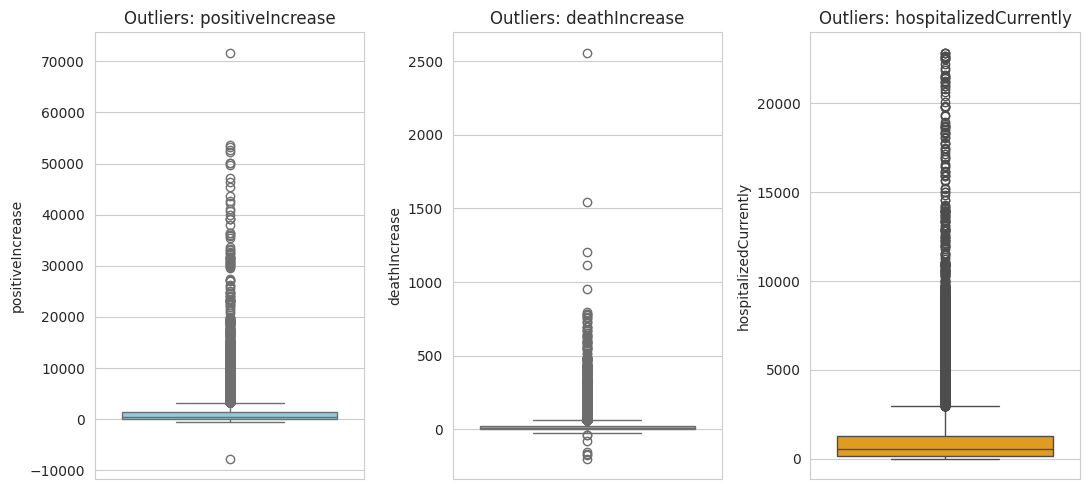

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(11, 5))

sns.boxplot(y=df_clean['positiveIncrease'], ax=axes[0], color='skyblue')
axes[0].set_title('Outliers: positiveIncrease')

sns.boxplot(y=df_clean['deathIncrease'], ax=axes[1], color='salmon')
axes[1].set_title('Outliers: deathIncrease')

sns.boxplot(y=df_clean['hospitalizedCurrently'], ax=axes[2], color='orange')
axes[2].set_title('Outliers: hospitalizedCurrently')

plt.tight_layout()
plt.show()

Rango Intercuartílico (IQR)

In [36]:
# Definimos una función genérica o aplicamos directamente la lógica sobre 'positiveIncrease'
columna = 'positiveIncrease'

Q1 = df_clean[columna].quantile(0.25)
Q3 = df_clean[columna].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")

# Opción A: Filtrar el DataFrame eliminando los outliers
df_sin_outliers = df_clean[(df_clean[columna] >= limite_inferior) & (df_clean[columna] <= limite_superior)]

# Opción B: Técnica de Winsorization (limitar los valores extremos al tope superior en vez de borrarlos)
# df_clean[columna] = np.where(df_clean[columna] > limite_superior, limite_superior, df_clean[columna])

Límite inferior: -1840.375
Límite superior: 3240.625


## 9. Pruebas de Hipótesis (Inferencia Estadística)
> ¿Son estadísticamente significativas las diferencias observadas en las métricas clave entre diferentes grupos (por ejemplo, entre regiones, estados o periodos temporales), o se deben a la variabilidad aleatoria?
>
> Planteamos hipótesis nulas ($H_0$) y alternativas ($H_1$) evaluando el valor $p$ ($p\text{-value}$) con un nivel de significancia del 5% ($\alpha = 0.05$).

--- 1. PRUEBA T DE STUDENT (CA vs NY) ---
Estadístico t: 7.5125
P-value: 2.8928e-13

--- 2. PRUEBA ANOVA (Estados líderes) ---
Estadístico F: 30.9907
P-value: 7.8355e-14



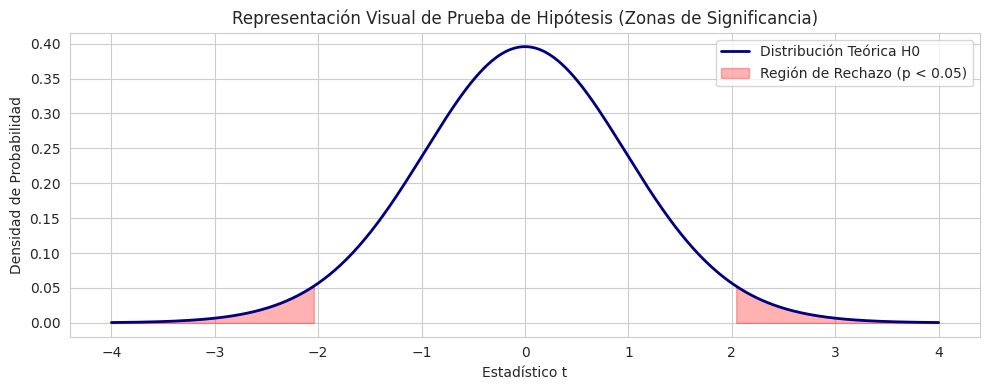

In [38]:
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt

# cálculo (Prueba t y ANOVA) ---
# Se seleccionan California (CA) y Nueva York (NY) por ser
# dos de los principales epicentros demográficos y de mayor volumen de contagios
# durante la pandemia en EE.UU., permitiendo evaluar si sus medias de crecimiento diario
# presentan diferencias estadísticamente significativas entre sí.
if 'state' in df_clean.columns:
    state_a = df_clean[df_clean['state'] == 'CA']['positiveIncrease'].dropna()
    state_b = df_clean[df_clean['state'] == 'NY']['positiveIncrease'].dropna()

    t_stat, p_val_ttest = stats.ttest_ind(state_a, state_b, equal_var=False)

    print("--- 1. PRUEBA T DE STUDENT (CA vs NY) ---")
    print(f"Estadístico t: {t_stat:.4f}")
    print(f"P-value: {p_val_ttest:.4e}\n")

# Se evalúan los 3 estados con mayor promedio de contagios
# para contrastar si al menos uno difiere significativamente del conjunto principal.
top_states = df_clean.groupby('state')['positiveIncrease'].mean().nlargest(3).index.tolist()
groups = [df_clean[df_clean['state'] == state]['positiveIncrease'].dropna() for state in top_states]
f_stat, p_val_anova = stats.f_oneway(*groups)

print("--- 2. PRUEBA ANOVA (Estados líderes) ---")
print(f"Estadístico F: {f_stat:.4f}")
print(f"P-value: {p_val_anova:.4e}\n")


# --- 2. visualización gráfica ---
plt.figure(figsize=(10, 4))
df_deg = 30
x = np.linspace(-4, 4, 1000)
y = stats.t.pdf(x, df_deg)

plt.plot(x, y, label='Distribución Teórica H0', color='navy', linewidth=2)

crit_val = stats.t.ppf(0.975, df_deg)
x_fill_right = np.linspace(crit_val, 4, 100)
plt.fill_between(x_fill_right, 0, stats.t.pdf(x_fill_right, df_deg), color='red', alpha=0.3, label='Región de Rechazo (p < 0.05)')

x_fill_left = np.linspace(-4, -crit_val, 100)
plt.fill_between(x_fill_left, 0, stats.t.pdf(x_fill_left, df_deg), color='red', alpha=0.3)

plt.title('Representación Visual de Prueba de Hipótesis (Zonas de Significancia)')
plt.xlabel('Estadístico t')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.tight_layout()

# Guardar figura para el Informe Ejecutivo
plt.savefig('figura_4_hipotesis.png', dpi=300)
plt.show()

## 10. Síntesis de Hallazgos y Conclusiones Estratégicas

Calidad: Variables de acumulados generales poseen <5% de nulos (alta confiabilidad), mientras que métricas operativas de UCI (inIcuCurrently) presentan ~44% de vacíos.

Distribución: Se observa una fuerte asimetría positiva en el volumen diario de contagios y muertes, caracterizada por picos episódicos severos durante las olas de contagio.

Dinámica: La serie temporal confirma un desfase estructural entre el pico de positivos y el consecuente incremento en hospitalizaciones y defunciones.